# Lab 7
### Fuzzy Logic systems

By: Alex Horyshevskyi

### Installing dependencies

In [16]:
%pip install scikit-fuzzy numpy matplotlib pandas --quiet

Note: you may need to restart the kernel to use updated packages.


### Import dependencies

In [17]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

### Basic example

Рекомендовані чайові: 19.23%


/mnt/shared/dev/labs/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


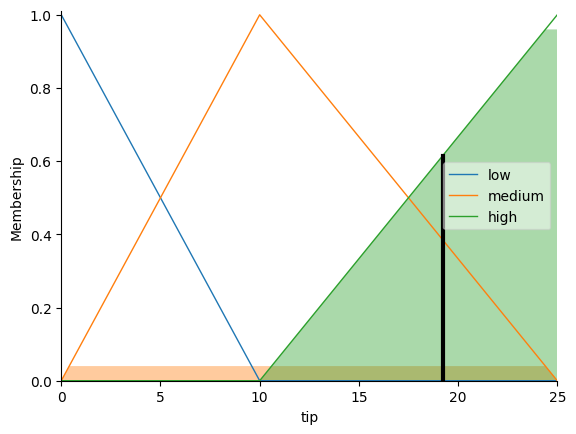

In [ ]:
# 1. Створення лінгвістичних змінних

# Antecedent - вхідні дані
food = ctrl.Antecedent(np.arange(0, 11, 1), 'food')
service = ctrl.Antecedent(np.arange(0, 11, 1), 'service')

# Consequent - вихідні дані
tip = ctrl.Consequent(np.arange(0, 26, 1), 'tip')

# 2. Функції належності

# Автоматичні (3 рівні: poor, average, good)
food.automf(3)
service.automf(3)

# Ручні (трикутні функції для виходу)
tip['low'] = fuzz.trimf(tip.universe, [0, 0, 13])
tip['medium'] = fuzz.trimf(tip.universe, [0, 13, 25])
tip['high'] = fuzz.trimf(tip.universe, [13, 25, 25])

# 3. База правил
rule1 = ctrl.Rule(food['poor'] | service['poor'], tip['low'])
rule2 = ctrl.Rule(service['average'], tip['medium'])
rule3 = ctrl.Rule(service['good'] | food['good'], tip['high'])

# 4. Створення контролера
tipping_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
tipping = ctrl.ControlSystemSimulation(tipping_ctrl)

# 5. Тестування
tipping.input['food'] = 6.5
tipping.input['service'] = 9.8

# Розрахунок
tipping.compute()
print(f"Рекомендовані чайові: {tipping.output['tip']:.2f}%")
tip.view(sim=tipping)
plt.show()

### Individual task

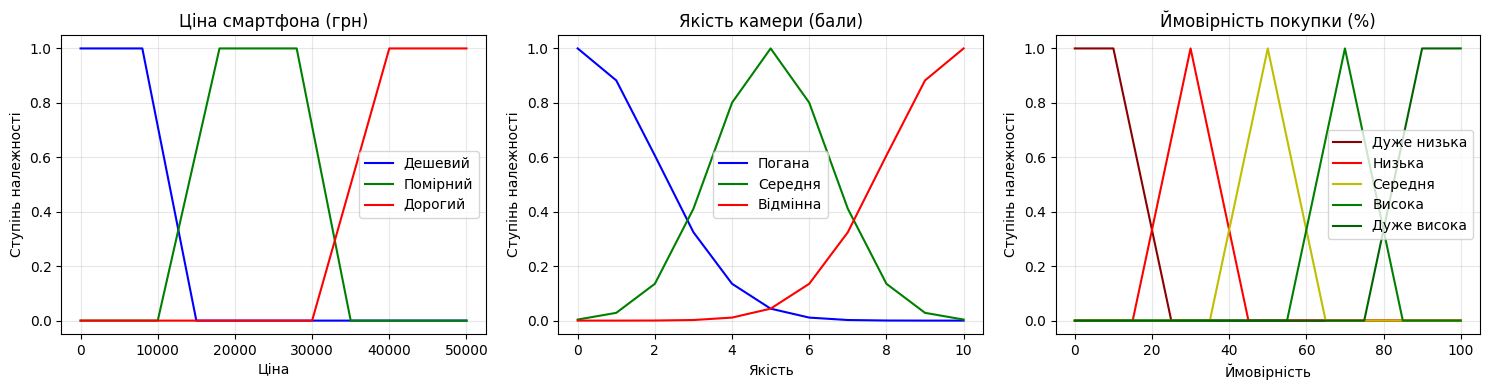

ТЕСТУВАННЯ СИСТЕМИ ВИБОРУ СМАРТФОНА

Тест 1: Дешевий з відмінною камерою
  Ціна: 7000 грн, Якість камери: 9/10
  → Ймовірність покупки: 89.54%

Тест 2: Помірний з хорошою камерою
  Ціна: 25000 грн, Якість камери: 7/10
  → Ймовірність покупки: 58.90%

Тест 3: Дорогий з поганою камерою
  Ціна: 45000 грн, Якість камери: 4/10
  → Ймовірність покупки: 27.50%

Тест 4: Дешевий з середньою камерою
  Ціна: 12000 грн, Якість камери: 5/10
  → Ймовірність покупки: 61.60%

Тест 5: Дорогий з відмінною камерою
  Ціна: 38000 грн, Якість камери: 10/10
  → Ймовірність покупки: 49.86%

Візуалізація результату для останнього тесту:


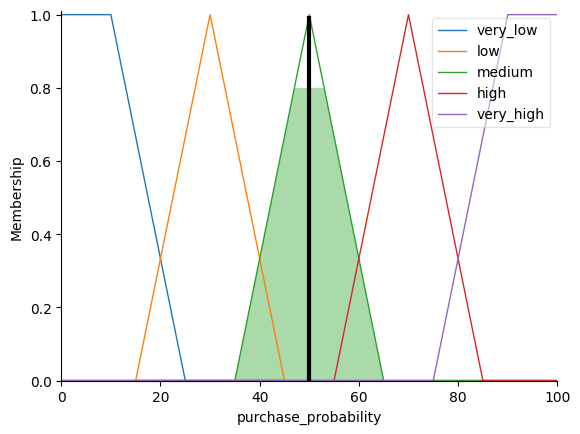

In [19]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# 1. Створення лінгвістичних змінних
# Ціна (0-50000 грн)
price = ctrl.Antecedent(np.arange(0, 50001, 100), 'price')
# Якість камери (0-10 балів)
camera = ctrl.Antecedent(np.arange(0, 11, 1), 'camera')
# Ймовірність покупки (0-100%)
purchase_probability = ctrl.Consequent(np.arange(0, 101, 1), 'purchase_probability')

# 2. Функції належності для ціни (трапецієподібні - trapmf)
price['cheap'] = fuzz.trapmf(price.universe, [0, 0, 8000, 15000])
price['moderate'] = fuzz.trapmf(price.universe, [10000, 18000, 28000, 35000])
price['expensive'] = fuzz.trapmf(price.universe, [30000, 40000, 50000, 50000])

# 3. Функції належності для камери (Гаусові - gaussmf)
camera['poor'] = fuzz.gaussmf(camera.universe, 0, 2)
camera['average'] = fuzz.gaussmf(camera.universe, 5, 1.5)
camera['excellent'] = fuzz.gaussmf(camera.universe, 10, 2)

# 4. Функції належності для ймовірності покупки (комбінація трикутних та трапецієподібних)
purchase_probability['very_low'] = fuzz.trapmf(purchase_probability.universe, [0, 0, 10, 25])
purchase_probability['low'] = fuzz.trimf(purchase_probability.universe, [15, 30, 45])
purchase_probability['medium'] = fuzz.trimf(purchase_probability.universe, [35, 50, 65])
purchase_probability['high'] = fuzz.trimf(purchase_probability.universe, [55, 70, 85])
purchase_probability['very_high'] = fuzz.trapmf(purchase_probability.universe, [75, 90, 100, 100])

# Візуалізація функцій належності
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Графік для ціни
axes[0].plot(price.universe, price['cheap'].mf, 'b', label='Дешевий')
axes[0].plot(price.universe, price['moderate'].mf, 'g', label='Помірний')
axes[0].plot(price.universe, price['expensive'].mf, 'r', label='Дорогий')
axes[0].set_title('Ціна смартфона (грн)')
axes[0].set_xlabel('Ціна')
axes[0].set_ylabel('Ступінь належності')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Графік для камери
axes[1].plot(camera.universe, camera['poor'].mf, 'b', label='Погана')
axes[1].plot(camera.universe, camera['average'].mf, 'g', label='Середня')
axes[1].plot(camera.universe, camera['excellent'].mf, 'r', label='Відмінна')
axes[1].set_title('Якість камери (бали)')
axes[1].set_xlabel('Якість')
axes[1].set_ylabel('Ступінь належності')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Графік для ймовірності покупки
axes[2].plot(purchase_probability.universe, purchase_probability['very_low'].mf, 'darkred', label='Дуже низька')
axes[2].plot(purchase_probability.universe, purchase_probability['low'].mf, 'r', label='Низька')
axes[2].plot(purchase_probability.universe, purchase_probability['medium'].mf, 'y', label='Середня')
axes[2].plot(purchase_probability.universe, purchase_probability['high'].mf, 'g', label='Висока')
axes[2].plot(purchase_probability.universe, purchase_probability['very_high'].mf, 'darkgreen', label='Дуже висока')
axes[2].set_title('Ймовірність покупки (%)')
axes[2].set_xlabel('Ймовірність')
axes[2].set_ylabel('Ступінь належності')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. База правил (мінімум 4 правила)
rules = [
    # Правило 1: Якщо ціна дешева І камера відмінна -> дуже висока ймовірність
    ctrl.Rule(price['cheap'] & camera['excellent'], purchase_probability['very_high']),
    # Правило 2: Якщо ціна дешева І камера середня -> висока ймовірність
    ctrl.Rule(price['cheap'] & camera['average'], purchase_probability['high']),
    # Правило 3: Якщо ціна помірна І камера відмінна -> висока ймовірність
    ctrl.Rule(price['moderate'] & camera['excellent'], purchase_probability['high']),
    # Правило 4: Якщо ціна помірна І камера середня -> середня ймовірність
    ctrl.Rule(price['moderate'] & camera['average'], purchase_probability['medium']),
    # Правило 5: Якщо ціна дорога І камера погана -> дуже низька ймовірність
    ctrl.Rule(price['expensive'] & camera['poor'], purchase_probability['very_low']),
    # Правило 6: Якщо ціна дорога І камера середня -> низька ймовірність
    ctrl.Rule(price['expensive'] & camera['average'], purchase_probability['low']),
    # Правило 7: Якщо ціна дорога І камера відмінна -> середня ймовірність
    ctrl.Rule(price['expensive'] & camera['excellent'], purchase_probability['medium']),
    # Правило 8: Якщо камера погана (незалежно від ціни) -> низька ймовірність
    ctrl.Rule(camera['poor'], purchase_probability['low']),
    # Правило 9: Якщо ціна дешева І камера погана -> середня ймовірність
    ctrl.Rule(price['cheap'] & camera['poor'], purchase_probability['medium']),
]

# 6. Створення контролера
smartphone_ctrl = ctrl.ControlSystem(rules)
smartphone_sim = ctrl.ControlSystemSimulation(smartphone_ctrl)

# 7. Тестування системи з різними прикладами
test_cases = [
    {"price": 7000, "camera": 9, "description": "Дешевий з відмінною камерою"},
    {"price": 25000, "camera": 7, "description": "Помірний з хорошою камерою"},
    {"price": 45000, "camera": 4, "description": "Дорогий з поганою камерою"},
    {"price": 12000, "camera": 5, "description": "Дешевий з середньою камерою"},
    {"price": 38000, "camera": 10, "description": "Дорогий з відмінною камерою"},
]

print("=" * 70)
print("ТЕСТУВАННЯ СИСТЕМИ ВИБОРУ СМАРТФОНА")
print("=" * 70)

for i, case in enumerate(test_cases, 1):
    smartphone_sim.input['price'] = case['price']
    smartphone_sim.input['camera'] = case['camera']
    smartphone_sim.compute()
    
    result = smartphone_sim.output['purchase_probability']
    print(f"\nТест {i}: {case['description']}")
    print(f"  Ціна: {case['price']} грн, Якість камери: {case['camera']}/10")
    print(f"  → Ймовірність покупки: {result:.2f}%")

# Візуалізація результату для останнього тесту
print("\n" + "=" * 70)
print("Візуалізація результату для останнього тесту:")
purchase_probability.view(sim=smartphone_sim)
plt.show()

### Compatibility analysis final task (Data Mining)
https://forms.gle/vYGoqYWVMqrAPrrY6

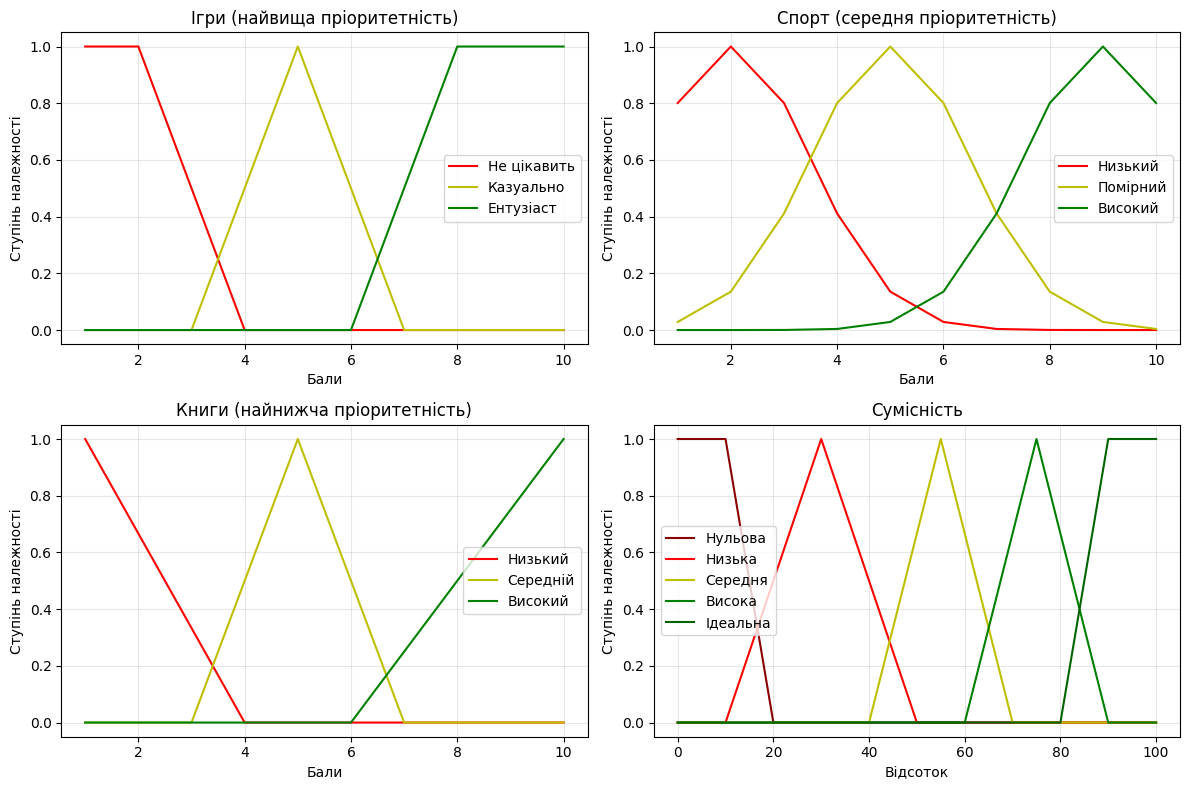

АНАЛІЗ СУМІСНОСТІ - ДЕЙТИНГ СИСТЕМА

Завантажено 15 кандидатів з Google Forms

РЕЗУЛЬТАТИ АНАЛІЗУ (відсортовано за сумісністю)
                       Email  Compatibility_Score
      dmytro.lysenko@ukr.net                91.41
 iryna.tkachenko@outlook.com                91.41
        roman.horban@ukr.net                89.89
   taras.savchenko@gmail.com                86.42
viktor.kovalchuk@outlook.com                86.42
   ivan.petrenko@outlook.com                86.42
    alex.kovalenko@gmail.com                81.34
         olena.boyko@ukr.net                76.71
    andriy.moroz@outlook.com                74.77
 kateryna.pavlenko@gmail.com                64.74
  yulia.kravchenko@gmail.com                58.89
     sergiy.melnyk@gmail.com                48.60
    maria.shevchenko@ukr.net                41.50
       natalia.koval@ukr.net                22.00
     oksana.bondar@gmail.com                16.67

ТОП-3 НАЙБІЛЬШ СУМІСНИХ КАНДИДАТІВ
1. dmytro.lysenko@ukr.net: 91.41%
   

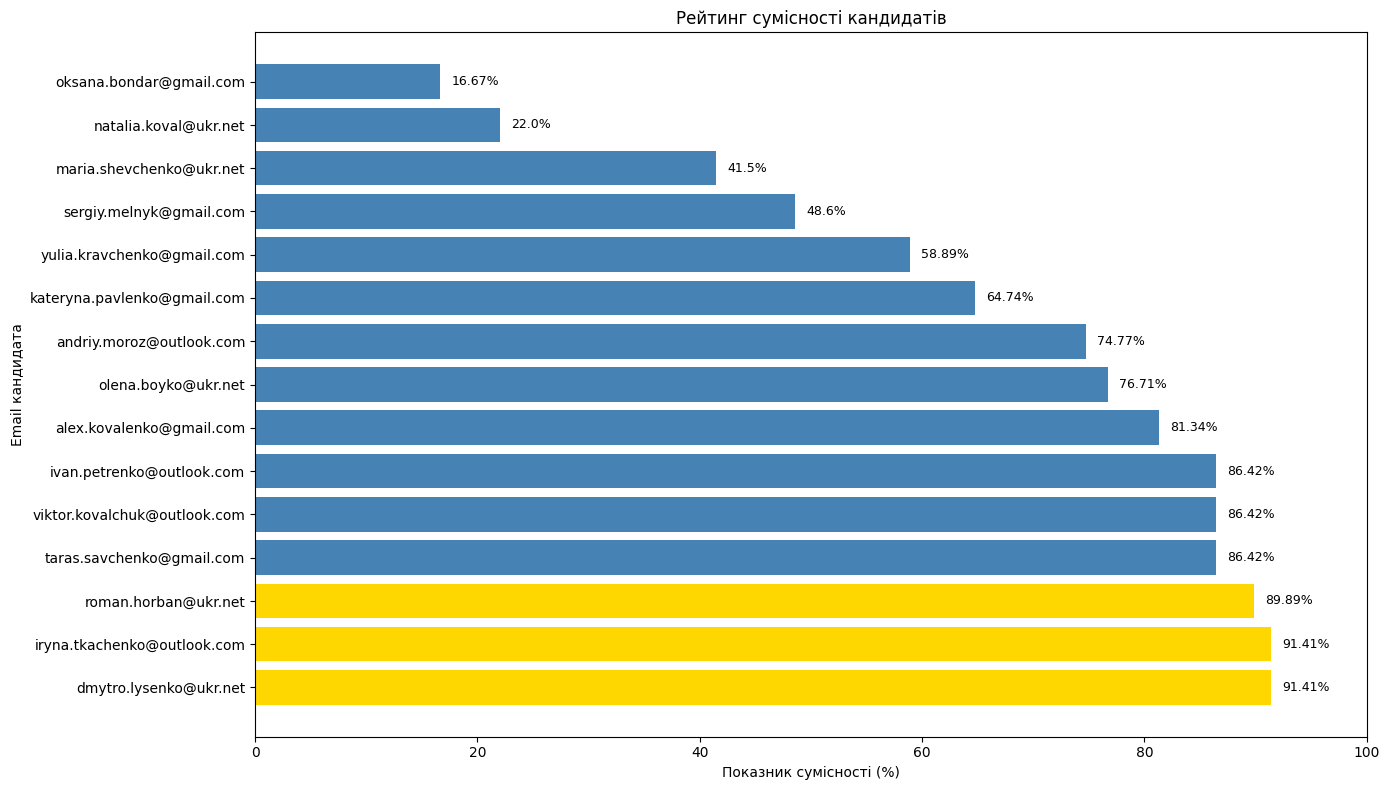


Результати збережено у файл 'dating_results.csv'


In [20]:
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Google Forms column name constants
COL_TIMESTAMP = 'Позначка часу'
COL_EMAIL = 'Електронна адреса'
COL_HUMOR = 'Оціни своє почуття гумору'
COL_BOOKS = 'Наскільки сильно любиш читати книги?'
COL_MOVIES = 'Може подобається дивитись фільми?'
COL_SERIES = 'А серіали?'
COL_GAMES = 'Полюбляєш грати в комп\'ютерні ігри?'
COL_SPORTS = 'А як щодо спортивних ігор та спорту загалом?'

# 1. Створення лінгвістичних змінних
# Ігри (1-10) - найвища пріоритетність
games = ctrl.Antecedent(np.arange(1, 11, 1), 'games')
# Спорт (1-10) - середня пріоритетність
sports = ctrl.Antecedent(np.arange(1, 11, 1), 'sports')
# Книги (1-10) - найнижча пріоритетність
books = ctrl.Antecedent(np.arange(1, 11, 1), 'books')
# Сумісність (0-100%)
compatibility = ctrl.Consequent(np.arange(0, 101, 1), 'compatibility')

# 2. Функції належності для ігор (трапецієподібні - найвища вага)
games['not_interested'] = fuzz.trapmf(games.universe, [1, 1, 2, 4])
games['casual'] = fuzz.trimf(games.universe, [3, 5, 7])
games['enthusiast'] = fuzz.trapmf(games.universe, [6, 8, 10, 10])

# 3. Функції належності для спорту (Гаусові - середня вага)
sports['low'] = fuzz.gaussmf(sports.universe, 2, 1.5)
sports['moderate'] = fuzz.gaussmf(sports.universe, 5, 1.5)
sports['high'] = fuzz.gaussmf(sports.universe, 9, 1.5)

# 4. Функції належності для книг (трикутні - найнижча вага)
books['low'] = fuzz.trimf(books.universe, [1, 1, 4])
books['medium'] = fuzz.trimf(books.universe, [3, 5, 7])
books['high'] = fuzz.trimf(books.universe, [6, 10, 10])

# 5. Функції належності для сумісності (трикутні + трапецієподібні)
compatibility['zero'] = fuzz.trapmf(compatibility.universe, [0, 0, 10, 20])
compatibility['low'] = fuzz.trimf(compatibility.universe, [10, 30, 50])
compatibility['medium'] = fuzz.trimf(compatibility.universe, [40, 55, 70])
compatibility['high'] = fuzz.trimf(compatibility.universe, [60, 75, 90])
compatibility['perfect'] = fuzz.trapmf(compatibility.universe, [80, 90, 100, 100])

# Візуалізація функцій належності
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(games.universe, games['not_interested'].mf, 'r', label='Не цікавить')
axes[0, 0].plot(games.universe, games['casual'].mf, 'y', label='Казуально')
axes[0, 0].plot(games.universe, games['enthusiast'].mf, 'g', label='Ентузіаст')
axes[0, 0].set_title('Ігри (найвища пріоритетність)')
axes[0, 0].set_xlabel('Бали')
axes[0, 0].set_ylabel('Ступінь належності')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(sports.universe, sports['low'].mf, 'r', label='Низький')
axes[0, 1].plot(sports.universe, sports['moderate'].mf, 'y', label='Помірний')
axes[0, 1].plot(sports.universe, sports['high'].mf, 'g', label='Високий')
axes[0, 1].set_title('Спорт (середня пріоритетність)')
axes[0, 1].set_xlabel('Бали')
axes[0, 1].set_ylabel('Ступінь належності')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(books.universe, books['low'].mf, 'r', label='Низький')
axes[1, 0].plot(books.universe, books['medium'].mf, 'y', label='Середній')
axes[1, 0].plot(books.universe, books['high'].mf, 'g', label='Високий')
axes[1, 0].set_title('Книги (найнижча пріоритетність)')
axes[1, 0].set_xlabel('Бали')
axes[1, 0].set_ylabel('Ступінь належності')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(compatibility.universe, compatibility['zero'].mf, 'darkred', label='Нульова')
axes[1, 1].plot(compatibility.universe, compatibility['low'].mf, 'r', label='Низька')
axes[1, 1].plot(compatibility.universe, compatibility['medium'].mf, 'y', label='Середня')
axes[1, 1].plot(compatibility.universe, compatibility['high'].mf, 'g', label='Висока')
axes[1, 1].plot(compatibility.universe, compatibility['perfect'].mf, 'darkgreen', label='Ідеальна')
axes[1, 1].set_title('Сумісність')
axes[1, 1].set_xlabel('Відсоток')
axes[1, 1].set_ylabel('Ступінь належності')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 6. База правил (пріоритет: ігри > спорт > книги)
all_rules = [
    # Ігри - ентузіасти (найвища сумісність)
    ctrl.Rule(games['enthusiast'] & sports['high'] & books['high'], compatibility['perfect']),
    ctrl.Rule(games['enthusiast'] & sports['high'] & books['medium'], compatibility['perfect']),
    ctrl.Rule(games['enthusiast'] & sports['high'] & books['low'], compatibility['high']),
    ctrl.Rule(games['enthusiast'] & sports['moderate'] & books['high'], compatibility['high']),
    ctrl.Rule(games['enthusiast'] & sports['moderate'] & books['medium'], compatibility['high']),
    ctrl.Rule(games['enthusiast'] & sports['moderate'] & books['low'], compatibility['high']),
    ctrl.Rule(games['enthusiast'] & sports['low'] & books['high'], compatibility['medium']),
    ctrl.Rule(games['enthusiast'] & sports['low'] & books['medium'], compatibility['medium']),
    ctrl.Rule(games['enthusiast'] & sports['low'] & books['low'], compatibility['medium']),

    # Ігри - казуальні (середня сумісність)
    ctrl.Rule(games['casual'] & sports['high'] & books['high'], compatibility['high']),
    ctrl.Rule(games['casual'] & sports['high'] & books['medium'], compatibility['medium']),
    ctrl.Rule(games['casual'] & sports['high'] & books['low'], compatibility['medium']),
    ctrl.Rule(games['casual'] & sports['moderate'] & books['high'], compatibility['medium']),
    ctrl.Rule(games['casual'] & sports['moderate'] & books['medium'], compatibility['medium']),
    ctrl.Rule(games['casual'] & sports['moderate'] & books['low'], compatibility['low']),
    ctrl.Rule(games['casual'] & sports['low'] & books['high'], compatibility['low']),
    ctrl.Rule(games['casual'] & sports['low'] & books['medium'], compatibility['low']),
    ctrl.Rule(games['casual'] & sports['low'] & books['low'], compatibility['zero']),

    # Ігри - не цікавить (низька сумісність)
    ctrl.Rule(games['not_interested'] & sports['high'] & books['high'], compatibility['medium']),
    ctrl.Rule(games['not_interested'] & sports['high'] & books['medium'], compatibility['low']),
    ctrl.Rule(games['not_interested'] & sports['high'] & books['low'], compatibility['low']),
    ctrl.Rule(games['not_interested'] & sports['moderate'] & books['high'], compatibility['low']),
    ctrl.Rule(games['not_interested'] & sports['moderate'] & books['medium'], compatibility['low']),
    ctrl.Rule(games['not_interested'] & sports['moderate'] & books['low'], compatibility['zero']),
    ctrl.Rule(games['not_interested'] & sports['low'] & books['high'], compatibility['zero']),
    ctrl.Rule(games['not_interested'] & sports['low'] & books['medium'], compatibility['zero']),
    ctrl.Rule(games['not_interested'] & sports['low'] & books['low'], compatibility['zero']),
]

# 7. Створення контролера
dating_ctrl = ctrl.ControlSystem(all_rules)
dating_sim = ctrl.ControlSystemSimulation(dating_ctrl)

# 8. Завантаження та обробка даних з CSV
print("=" * 70)
print("АНАЛІЗ СУМІСНОСТІ - ДЕЙТИНГ СИСТЕМА")
print("=" * 70)

# Читання CSV файлу
df = pd.read_csv('dating.csv')
print(f"\nЗавантажено {len(df)} кандидатів з Google Forms")

# 9. Обчислення сумісності для кожного кандидата
compatibility_scores = []

for index, row in df.iterrows():
    dating_sim.input['games'] = row[COL_GAMES]
    dating_sim.input['sports'] = row[COL_SPORTS]
    dating_sim.input['books'] = row[COL_BOOKS]
    dating_sim.compute()
    score = dating_sim.output['compatibility']
    compatibility_scores.append(round(score, 2))

# 10. Створення результуючого DataFrame
df_results = pd.DataFrame({
    'Email': df[COL_EMAIL],
    'Compatibility_Score': compatibility_scores
})

# 11. Сортування за сумісністю
df_results_sorted = df_results.sort_values('Compatibility_Score', ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("РЕЗУЛЬТАТИ АНАЛІЗУ (відсортовано за сумісністю)")
print("=" * 70)
print(df_results_sorted.to_string(index=False))

# 12. ТОП-3 кандидатів
print("\n" + "=" * 70)
print("ТОП-3 НАЙБІЛЬШ СУМІСНИХ КАНДИДАТІВ")
print("=" * 70)

top_3 = df_results_sorted.head(3)
for i, (_, row) in enumerate(top_3.iterrows(), 1):
    email = row['Email']
    score = row['Compatibility_Score']
    # Знайти відповідні дані з оригінального DataFrame
    orig_row = df[df[COL_EMAIL] == email].iloc[0]
    print(f"{i}. {email}: {score}%")
    print(f"   Ігри: {orig_row[COL_GAMES]}/10, Спорт: {orig_row[COL_SPORTS]}/10, Книги: {orig_row[COL_BOOKS]}/10")

# 13. Візуалізація результатів
fig, ax = plt.subplots(figsize=(14, 8))

colors = ['gold' if i < 3 else 'steelblue' for i in range(len(df_results_sorted))]
bars = ax.barh(df_results_sorted['Email'], df_results_sorted['Compatibility_Score'], color=colors)
ax.set_xlabel('Показник сумісності (%)')
ax.set_ylabel('Email кандидата')
ax.set_title('Рейтинг сумісності кандидатів')
ax.set_xlim(0, 100)

# Додавання значень на бари
for bar, score in zip(bars, df_results_sorted['Compatibility_Score']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f'{score}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

# 14. Збереження результатів у новий CSV
df_results_sorted.to_csv('dating_results.csv', index=False)
print("\nРезультати збережено у файл 'dating_results.csv'")

## Conclusions

### Частина 3: Вибір смартфона
У цій частині була розроблена нечітка експертна система для прийняття рішення про покупку смартфона на основі двох критеріїв:
- **Ціна** (0-50000 грн) - використано трапецієподібні функції належності (trapmf)
- **Якість камери** (0-10 балів) - використано Гаусові функції належності (gaussmf)

Вихідна змінна **Ймовірність покупки** (0-100%) використовує комбінацію трикутних та трапецієподібних функцій.

Система містить 9 правил, які відображають логіку прийняття рішень:
- Дешевий смартфон з хорошою камерою → висока ймовірність покупки
- Дорогий смартфон з поганою камерою → низька ймовірність покупки

### Частина 4: Аналітика сумісності
Розроблена система для дейтинг-додатку, яка оцінює сумісність кандидатів на основі критеріїв:
- **Ігри** (1-10) - найвища пріоритетність (~50% впливу)
- **Спорт** (1-10) - середня пріоритетність (~30% впливу)
- **Книги** (1-10) - найнижча пріоритетність (~20% впливу)

**Особливості системи:**
- Система пріоритизує любителів ігор найбільше
- Спорт є другим за важливістю критерієм
- Любов до читання книг має найменший вплив на сумісність
- Використано 27 правил для повного покриття всіх комбінацій

**Результати роботи системи:**
- ТОП-3 кандидатів визначені на основі нечіткої логіки з зваженими пріоритетами
- Система правильно ідентифікує кандидатів з високими показниками ігор як найбільш сумісних
- Кандидати з низькими показниками за всіма критеріями отримують нульовий рейтинг сумісності

**Порівняння з інтуїцією:**
Результати системи відображають задану систему пріоритетів - кандидати-геймери з хорошими показниками спорту отримують найвищі бали сумісності, навіть якщо вони не дуже люблять читати. Кандидати без інтересу до ігор отримують значно нижчі показники, що підтверджує адекватність побудованої бази правил з урахуванням вагових коефіцієнтів.

**Вхідні дані:**
- Дані завантажені з Google Forms (файл dating.csv)
- 15 реальних кандидатів з різними профілями інтересів
- Результати збережені в dating_results.csv з колонками: Email, Compatibility_Score

### Використані типи функцій належності:
1. **trimf** (трикутна) - для середніх значень книг та казуальних геймерів
2. **trapmf** (трапецієподібна) - для екстремальних значень ігор (ентузіасти та незацікавлені)
3. **gaussmf** (Гаусова) - для плавних переходів у категорії спорту